In [1]:
import pandas as pd

df = pd.read_csv("housing.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset Loaded Successfully!
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
media

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [4]:
# Fill numerical missing values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled successfully!")

print(df.isnull().sum())

Missing values handled successfully!
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries ready!")

Libraries ready!


In [7]:
# Create interaction and ratio features

df["rooms_per_household"] = (
    df["total_rooms"] / df["households"].replace(0, np.nan)
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"].replace(0, np.nan)
)

df["population_per_household"] = (
    df["population"] / df["households"].replace(0, np.nan)
)

df["income_house_age"] = (
    df["median_income"] * df["housing_median_age"]
)

# Handle new missing values
df = df.fillna(df.median(numeric_only=True))

print("Feature Engineering Completed!")
print(df.head())

Feature Engineering Completed!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  \
0       322.0       126.0         8.3252            452600.0        NEAR BAY   
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY   
2       496.0       177.0         7.2574            352100.0        NEAR BAY   
3       558.0       219.0         5.6431            341300.0        NEAR BAY   
4       565.0       259.0         3.8462            342200.0        NEAR BAY   

   rooms_per_household  bedrooms_per_

In [8]:
# Input features
X = df.drop("median_house_value", axis=1)

# Target variable
y = df["median_house_value"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Columns:")
print(X.columns.tolist())

Input Features Shape: (20640, 13)
Target Shape: (20640,)

Input Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_house_age']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Train-Test Split Completed!")

Training Data: (16512, 13)
Testing Data: (4128, 13)
Train-Test Split Completed!


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed!")
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Preprocessing Completed!
Training Shape: (16512, 17)
Testing Shape: (4128, 17)


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create OLS model
ols_model = LinearRegression()

# Train model
ols_model.fit(X_train_processed, y_train)

# Predictions
ols_predictions = ols_model.predict(X_test_processed)

# Evaluation
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_r2 = r2_score(y_test, ols_predictions)

print("OLS Regression Results")
print("----------------------")
print("RMSE:", ols_rmse)
print("MAE:", ols_mae)
print("R2 Score:", ols_r2)

OLS Regression Results
----------------------
RMSE: 72803.24212495863
MAE: 50602.6965282265
R2 Score: 0.5955223024325947


In [12]:
from sklearn.linear_model import Ridge

# Create Ridge model
ridge_model = Ridge(alpha=1.0)

# Train model
ridge_model.fit(X_train_processed, y_train)

# Predictions
ridge_predictions = ridge_model.predict(X_test_processed)

# Evaluation
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression Results")
print("------------------------")
print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2 Score:", ridge_r2)

Ridge Regression Results
------------------------
RMSE: 72812.88235040933
MAE: 50611.31543115953
R2 Score: 0.595415177688144


In [13]:
from sklearn.linear_model import Lasso

# Create Lasso model
lasso_model = Lasso(alpha=0.1, max_iter=10000)

# Train model
lasso_model.fit(X_train_processed, y_train)

# Predictions
lasso_predictions = lasso_model.predict(X_test_processed)

# Evaluation
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_mae = mean_absolute_error(y_test, lasso_predictions)
lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression Results")
print("------------------------")
print("RMSE:", lasso_rmse)
print("MAE:", lasso_mae)
print("R2 Score:", lasso_r2)

Lasso Regression Results
------------------------
RMSE: 72803.32428145276
MAE: 50602.82486774878
R2 Score: 0.5955213895477461


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.085e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [14]:
from sklearn.model_selection import GridSearchCV

# Ridge Hyperparameter Tuning
ridge_grid = GridSearchCV(
    Ridge(),
    {"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=3,
    scoring="neg_mean_squared_error"
)

ridge_grid.fit(X_train_processed, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge Score:", -ridge_grid.best_score_)


# Lasso Hyperparameter Tuning
lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    {"alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=3,
    scoring="neg_mean_squared_error"
)

lasso_grid.fit(X_train_processed, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_)
print("Best Lasso Score:", -lasso_grid.best_score_)

Best Ridge Alpha: {'alpha': 0.1}
Best Ridge Score: 4600383514.428222


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.030e+12, tolerance: 1.465e+10
  model = cd_fast.enet_coordinate_descent(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.127e+12, tolerance: 1.485e+10
  model = cd_fast.enet_coordinate_descent(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the sca

Best Lasso Alpha: {'alpha': 10}
Best Lasso Score: 4599914159.235086


In [15]:
results = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [ols_rmse, ridge_rmse, lasso_rmse],
    "MAE": [ols_mae, ridge_mae, lasso_mae],
    "R2 Score": [ols_r2, ridge_r2, lasso_r2]
})

print("Model Comparison:")
display(results)

# Best model based on RMSE
best_model_name = results.loc[results["RMSE"].idxmin(), "Model"]

print("Best Model:", best_model_name)

Model Comparison:


,Model,RMSE,MAE,R2 Score
0,OLS,72803.242125,50602.696528,0.595522
1,Ridge,72812.882350,50611.315431,0.595415
2,Lasso,72803.324281,50602.824868,0.595521


Best Model: OLS


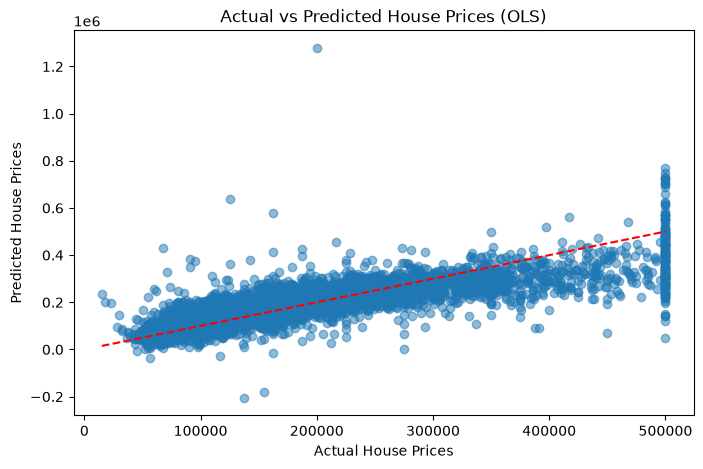

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, ols_predictions, alpha=0.5)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices (OLS)")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.show()

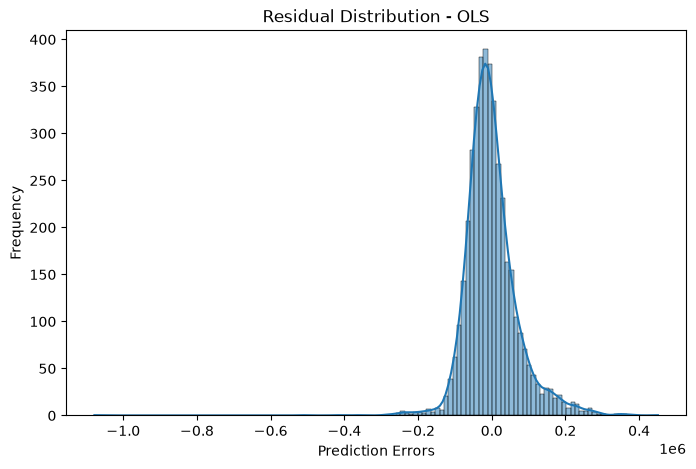

In [17]:
# Calculate residuals
residuals = y_test - ols_predictions

# Plot residual distribution
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution - OLS")
plt.xlabel("Prediction Errors")
plt.ylabel("Frequency")

plt.show()

In [18]:
# Best tuned Ridge and Lasso models
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

models = {
    "OLS": ols_model,
    "Ridge Tuned": best_ridge,
    "Lasso Tuned": best_lasso
}

for name, model in models.items():
    predictions = model.predict(X_test_processed)

    print("\n", name)
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("R2 Score:", r2_score(y_test, predictions))


 OLS
RMSE: 72803.24212495863
MAE: 50602.6965282265
R2 Score: 0.5955223024325947

 Ridge Tuned
RMSE: 72804.3107296247
MAE: 50603.721171874844
R2 Score: 0.5955104285128507

 Lasso Tuned
RMSE: 72810.52855159489
MAE: 50612.82078668482
R2 Score: 0.5954413350342571


In [19]:
import joblib

best_model = min(
    models.items(),
    key=lambda item: np.sqrt(
        mean_squared_error(y_test, item[1].predict(X_test_processed))
    )
)

joblib.dump(best_model[1], "best_house_price_model.pkl")
joblib.dump(preprocessor, "house_price_preprocessor.pkl")

print("Best Model:", best_model[0])
print("Model saved successfully!")

Best Model: OLS
Model saved successfully!
